In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
conn=sqlite3.connect("../data/checking-logs.sqlite")

In [3]:
df=pd.read_sql("select * from checker where uid like 'user_%'",conn)
df=df[['timestamp','uid']]
df['timestamp']=pd.to_datetime(df['timestamp'])
df['days']=df['timestamp'].dt.date
df['day_i']=df['timestamp'].dt.weekday
df['weekdays']=df['timestamp'].dt.day_name()
df['hour']=df['timestamp'].dt.hour

In [4]:
df

,timestamp,uid,days,day_i,weekdays,hour
0,2020-04-17 05:19:02.744528,user_4,2020-04-17,4,Friday,5
1,2020-04-17 05:22:35.249331,user_4,2020-04-17,4,Friday,5
2,2020-04-17 05:22:45.549397,user_4,2020-04-17,4,Friday,5
3,2020-04-17 05:34:14.691200,user_4,2020-04-17,4,Friday,5
4,2020-04-17 05:34:24.422370,user_4,2020-04-17,4,Friday,5
...,...,...,...,...,...,...
3202,2020-05-21 20:19:06.872761,user_1,2020-05-21,3,Thursday,20
3203,2020-05-21 20:22:41.785725,user_1,2020-05-21,3,Thursday,20
3204,2020-05-21 20:22:41.877806,user_1,2020-05-21,3,Thursday,20
3205,2020-05-21 20:37:00.129678,user_1,2020-05-21,3,Thursday,20


In [5]:
weekday=df.groupby(['day_i','weekdays','uid']).size().reset_index(name='commits')
hours=df.groupby(['hour','uid']).size().reset_index(name='commits')

In [6]:
weekday=weekday.sort_values('commits',ascending=False)
weekday_pivot=weekday.pivot(index=['day_i','weekdays'],columns='uid',values='commits').fillna(0)
weekday_pivot=weekday_pivot.droplevel('day_i')
weekday_pivot

uid,user_0,user_1,user_10,user_11,user_12,user_13,user_14,user_15,user_16,user_17,...,user_27,user_28,user_29,user_3,user_30,user_31,user_4,user_6,user_7,user_8
weekdays,,,,,,,,,,,,,,,,,,,,,
Monday,3.0,0.0,0.0,0.0,2.0,3.0,50.0,0.0,10.0,8.0,...,0.0,0.0,9.0,46.0,2.0,5.0,35.0,1.0,0.0,0.0
Tuesday,0.0,0.0,16.0,0.0,1.0,57.0,87.0,0.0,5.0,4.0,...,0.0,7.0,26.0,11.0,3.0,0.0,86.0,0.0,5.0,0.0
Wednesday,0.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,44.0,32.0,0.0,1.0,0.0,33.0,4.0,3.0,0.0
Thursday,0.0,39.0,77.0,0.0,7.0,4.0,17.0,5.0,14.0,17.0,...,15.0,12.0,25.0,7.0,20.0,7.0,108.0,2.0,0.0,15.0
Friday,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,7.0,1.0,59.0,3.0,35.0,61.0,0.0,0.0,0.0
Saturday,0.0,1.0,4.0,0.0,7.0,28.0,79.0,4.0,0.0,32.0,...,0.0,12.0,2.0,3.0,22.0,90.0,0.0,2.0,0.0,46.0
Sunday,0.0,43.0,2.0,8.0,76.0,23.0,26.0,20.0,31.0,0.0,...,27.0,32.0,26.0,8.0,21.0,7.0,45.0,9.0,0.0,26.0


In [7]:
hours=hours.sort_values('commits',ascending=False)
hours

,hour,uid,commits
283,21,user_4,86
72,11,user_31,70
257,20,user_4,53
232,19,user_29,45
275,21,user_25,43
...,...,...,...
40,9,user_29,1
256,20,user_31,1
51,10,user_24,1
26,8,user_23,1


In [8]:
hours_pivot=hours.pivot(index='hour',columns='uid',values='commits').fillna(0)
hours_pivot

uid,user_0,user_1,user_10,user_11,user_12,user_13,user_14,user_15,user_16,user_17,...,user_27,user_28,user_29,user_3,user_30,user_31,user_4,user_6,user_7,user_8
hour,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,0.0,2.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,13.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,3.0,0.0,0.0,20.0,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,9.0,0.0,10.0,11.0,6.0,0.0,0.0,2.0,...,0.0,0.0,0.0,6.0,2.0,0.0,0.0,0.0,1.0,6.0
9,0.0,0.0,0.0,0.0,10.0,10.0,4.0,2.0,0.0,0.0,...,0.0,0.0,1.0,3.0,2.0,1.0,0.0,0.0,0.0,0.0
10,0.0,0.0,0.0,0.0,10.0,8.0,2.0,0.0,0.0,7.0,...,0.0,2.0,0.0,2.0,0.0,0.0,26.0,0.0,0.0,5.0


/tmp/ipykernel_272624/3885650119.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


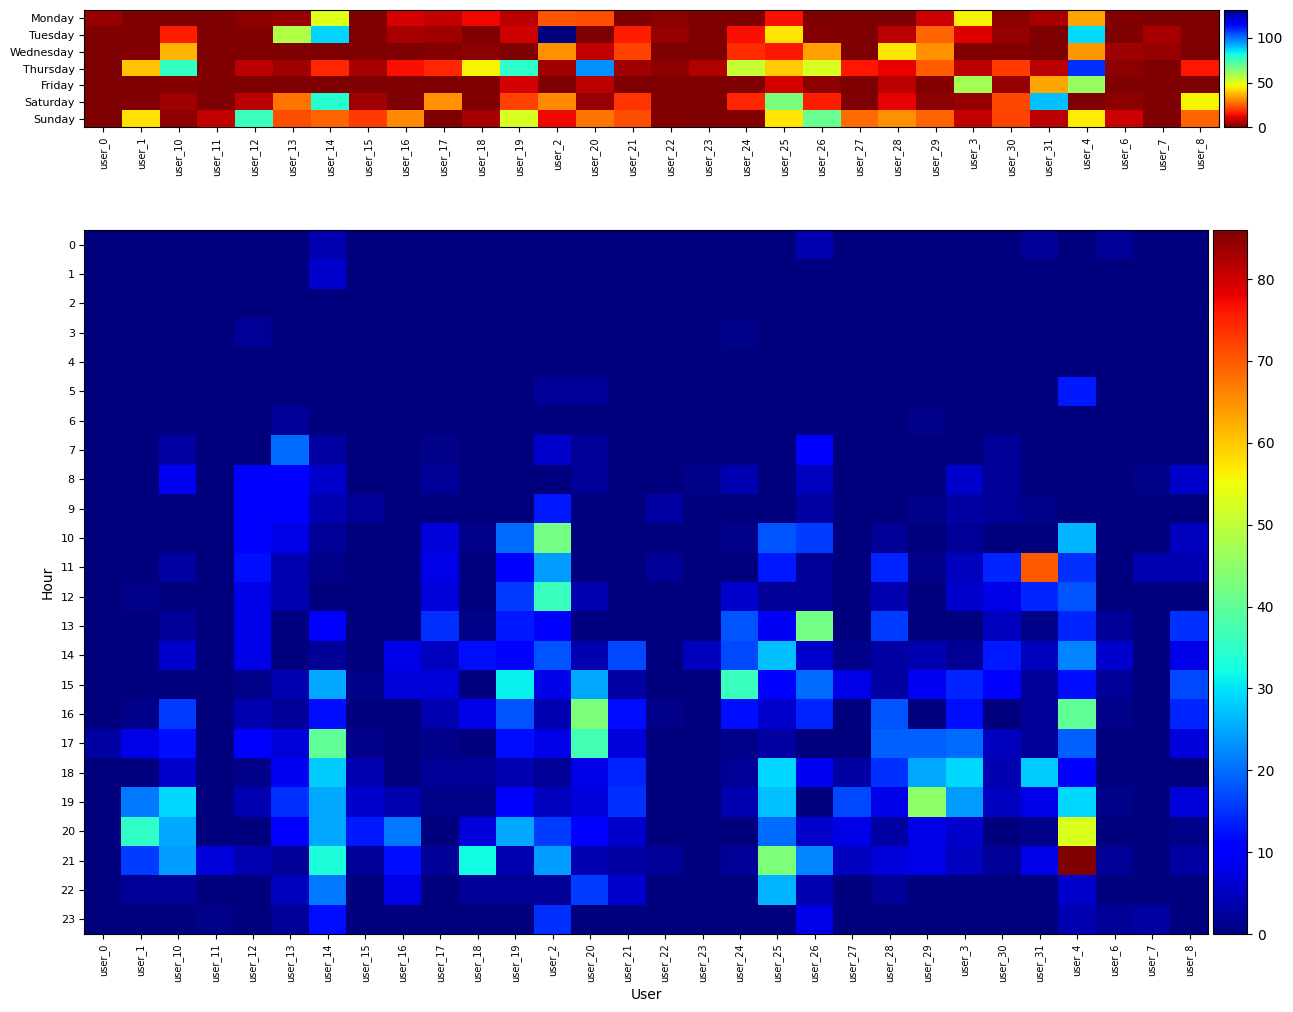

In [9]:
# Draw two stacked heatmaps using only matplotlib and make_axes_locatable
plt.close('all')

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(15,12),
                               gridspec_kw={'height_ratios': [1, 6], 'hspace': 0.25})

# Ensure weekdays are in natural order (Mon..Sun)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_plot = weekday_pivot.reindex(weekday_order).fillna(0)

# Top: weekday heatmap (compact) using imshow
data_w = weekday_plot.values
im1 = ax1.imshow(data_w, aspect='auto', cmap='jet_r', interpolation='nearest', origin='upper')

# ticks and labels
ax1.set_xticks(range(len(weekday_plot.columns)))
ax1.set_xticklabels(weekday_plot.columns, rotation=90, fontsize=7)
ax1.set_yticks(range(len(weekday_plot.index)))
ax1.set_yticklabels(weekday_plot.index, rotation=0, fontsize=8)
ax1.set_ylabel('')
ax1.set_xlabel('')

# colorbar for weekday heatmap
divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", size="2%", pad=0.05)
fig.colorbar(im1, cax=cax1)

# Bottom: hourly heatmap (larger)
# Ensure hours index covers 0..23 for consistent display
hours_plot = hours_pivot.reindex(range(24)).fillna(0)
data_h = hours_plot.values
im2 = ax2.imshow(data_h, aspect='auto', cmap='jet', interpolation='nearest', origin='upper')

# ticks and labels
ax2.set_xticks(range(len(hours_plot.columns)))
ax2.set_xticklabels(hours_plot.columns, rotation=90, fontsize=7)
ax2.set_yticks(range(len(hours_plot.index)))
ax2.set_yticklabels(hours_plot.index, rotation=0, fontsize=8)
ax2.set_ylabel('Hour')
ax2.set_xlabel('User')

# colorbar for hourly heatmap
divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", size="3%", pad=0.05)
fig.colorbar(im2, cax=cax2)

fig.tight_layout()
plt.show()

In [10]:
weekday[weekday['weekdays']=='Tuesday'].sort_values('commits',ascending=False)[:1]

,day_i,weekdays,uid,commits
25,1,Tuesday,user_2,131


In [11]:
weekday[weekday['weekdays']=='Thursday'].sort_values('commits',ascending=False)[:1]

,day_i,weekdays,uid,commits
77,3,Thursday,user_4,108


In [12]:
weekday.groupby('weekdays')['commits'].sum().reset_index().sort_values('commits',ascending=True)[:1]

,weekdays,commits
0,Friday,196


In [13]:
hours.sort_values('commits',ascending=False)[:1]

,hour,uid,commits
283,21,user_4,86


In [14]:
conn.close()

Which user has the most commits on Tuesday?

user_2

Which user has the most commits on Thursday?

user_4

On which weekday do users not like to make a lot of commits?

Friday

Which user made the largest number of commits at which hour?

user_4, 21